In [15]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


### Combine all features with the target groundwater data

In [16]:
import pandas as pd
import numpy as np
import geopandas as gpd
import matplotlib.pyplot as plt
import seaborn as sns
import json
import requests

In [17]:
import sys
from pathlib import Path

# Root directory
cwd = Path.cwd()
ROOT = next(p for p in [cwd, *cwd.parents] if (p / ".git").exists())
sys.path.append(str(ROOT))

# Location of data
DATA = ROOT / "data"

# Location of notebooks
NOTEBOOKS = ROOT / "notebooks"


# Directory and name of watershed boundary file
watershed_bd = DATA / "watershed_boundary"
ws_bd_name = "salinas_huc8"

# Source for watershed boundary
WBD_URL = "https://hydro.nationalmap.gov/arcgis/rest/services/wbd/MapServer"
huc8_code = "18060005"


# Soils data
soil_dir = DATA / "datasets" / "merge"      # Location of cleaned soil polygons
soil_polygons = "soil_polygons"     # Name of soil polygons file
soils_source = DATA / "datasets" / "ssurgo_soildata"        # SSURGO data, Web Soil Survey areas CA053, CA069, CA665, CA772, CA788
soil_attributes = ROOT / "notebooks" / "soils" / "soils_clean.csv"      # Source for soil attributes


# INMP data
layer_key={"INMP_map": 0, "nitrate_risk": 1, "crop_mapping": 2}     # Layer key
layer_names = layer_key.keys()      # List of layer names
INMP_url = "https://gispublic.waterboards.ca.gov/portalserver/rest/services/Hosted/Region_3_INMP_Data_Map/FeatureServer"        # Source for INMP data
full_dir = DATA / "datasets" / "inmp" / "full"      # Directory for full INMP layers
clipped_dir = DATA / "datasets" / "inmp" / "clipped"        # Directory for clipped INMP layers


# Groundwater data
gw_path = NOTEBOOKS / "groundwater" / "groundwater_nitrate_clean.csv"

# Groundwater Thiessen polygons
gwdt_path = NOTEBOOKS / "groundwater_depth" / "thiessen_polygons.gpkg"

# Surface water Thiessen polygons
swt_path = NOTEBOOKS / "surface_water" / "thiessen_polygons.gpkg"

In [18]:
from src.shared import arcgis, spatial, io
from src.merge import merging_functions, soils
from src import inmp

#### Watershed boundary

In [19]:
boundary_path = watershed_bd / f"{ws_bd_name}.gpkg"

if boundary_path.exists():
    huc8 = spatial.load_boundary(boundary_path)
else:
    huc8 = spatial.fetch_huc8(WBD_URL, huc8_code)
    boundary_path.parent.mkdir(parents=True, exist_ok=True)
    huc8.to_file(boundary_path)

#### 1. Groundwater depth

In [20]:
merged_df = merging_functions.merge_csv_with_polygons(
    csv_path=NOTEBOOKS / "groundwater" / "groundwater_nitrate_clean.csv",
    polygon_path= NOTEBOOKS / "groundwater_depth" / "thiessen_polygons.gpkg",
    output_path="merged.csv",
    lat_col="gm_latitude",
    lon_col="gm_longitude"
)

#### 2. Surface water nitrate measurements

In [21]:
merged_df = merging_functions.merge_csv_with_polygons(
    csv_path="merged.csv",
    polygon_path= NOTEBOOKS / "surface_water" / "thiessen_polygons.gpkg",
    output_path="merged.csv",
    lat_col="gm_latitude",
    lon_col="gm_longitude"
)

In [22]:
merged_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5280 entries, 0 to 5279
Data columns (total 20 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   gm_well_id               5280 non-null   str    
 1   gm_well_category         5280 non-null   str    
 2   gm_samp_collection_date  5280 non-null   str    
 3   gm_latitude              5280 non-null   float64
 4   gm_longitude             5280 non-null   float64
 5   nitrate_mg_L             5280 non-null   float64
 6   year                     5280 non-null   int64  
 7   well_name                5280 non-null   str    
 8   latitude                 5280 non-null   float64
 9   longitude                5280 non-null   float64
 10  gse                      5280 non-null   float64
 11  rpe                      5280 non-null   float64
 12  gse_method               5280 non-null   str    
 13  county_name              5280 non-null   str    
 14  well_depth               5280 non-n

In [23]:
merged_df.head()

,gm_well_id,gm_well_category,gm_samp_collection_date,gm_latitude,gm_longitude,nitrate_mg_L,year,well_name,latitude,longitude,gse,rpe,gse_method,county_name,well_depth,well_use,well_type,polygon_latitude,polygon_longitude,result_mg_l
0,AGL020000465-PRIMARY,Domestic,2022-05-04 09:40:00,35.551290,-120.600420,3.12,2022,PASO-0423,35.54884,-120.60999,1090.23,1090.23,Digital Elevation Model,San Luis Obispo,685.0,Irrigation,Single Well,35.492928,-120.64574,0.6
1,AGL020000465-PRIMARY,Domestic,2023-06-07 11:45:00,35.551290,-120.600420,2.97,2023,PASO-0423,35.54884,-120.60999,1090.23,1090.23,Digital Elevation Model,San Luis Obispo,685.0,Irrigation,Single Well,35.492928,-120.64574,0.6
2,AGL020000465-PRIMARY,Domestic,2024-05-16 08:00:00,35.551290,-120.600420,3.38,2024,PASO-0423,35.54884,-120.60999,1090.23,1090.23,Digital Elevation Model,San Luis Obispo,685.0,Irrigation,Single Well,35.492928,-120.64574,0.6
3,AGL020000465-PRIMARY,Domestic,2025-04-14 08:00:00,35.551290,-120.600420,3.14,2025,PASO-0423,35.54884,-120.60999,1090.23,1090.23,Digital Elevation Model,San Luis Obispo,685.0,Irrigation,Single Well,35.492928,-120.64574,0.6
4,AGL020000484-ROOS-HOMESTEAD,Domestic,2022-05-18 12:50:00,35.515854,-120.640089,3.82,2022,28S/12E-11K02,35.50861,-120.65250,882.00,882.00,Unknown,San Luis Obispo,603.0,Other,Single Well,35.492928,-120.64574,0.6


In [24]:
DEPTH_COLS = ["well_name", "well_depth", "gse"]
SW_COLS = ["result_mg_l"]

samples = pd.read_csv(gw_path)
depth_thiessen = gpd.read_file(gwdt_path)
sw_thiessen = gpd.read_file(swt_path)


merged = (merging_functions.to_points(samples, "gm_longitude", "gm_latitude").pipe(
    merging_functions.attach_polygons, depth_thiessen, DEPTH_COLS, "depth_"
).pipe(
    merging_functions.attach_polygons, sw_thiessen, SW_COLS, "sw_"
))

In [25]:
merged.head()

,gm_well_id,gm_well_category,gm_samp_collection_date,gm_latitude,gm_longitude,nitrate_mg_L,year,geometry,depth_well_name,depth_well_depth,depth_gse,sw_result_mg_l
0,AGL020000465-PRIMARY,Domestic,2022-05-04 09:40:00,35.551290,-120.600420,3.12,2022,POINT (-120.60042 35.55129),PASO-0423,685.0,1090.23,0.6
1,AGL020000465-PRIMARY,Domestic,2023-06-07 11:45:00,35.551290,-120.600420,2.97,2023,POINT (-120.60042 35.55129),PASO-0423,685.0,1090.23,0.6
2,AGL020000465-PRIMARY,Domestic,2024-05-16 08:00:00,35.551290,-120.600420,3.38,2024,POINT (-120.60042 35.55129),PASO-0423,685.0,1090.23,0.6
3,AGL020000465-PRIMARY,Domestic,2025-04-14 08:00:00,35.551290,-120.600420,3.14,2025,POINT (-120.60042 35.55129),PASO-0423,685.0,1090.23,0.6
4,AGL020000484-ROOS-HOMESTEAD,Domestic,2022-05-18 12:50:00,35.515854,-120.640089,3.82,2022,POINT (-120.64009 35.51585),28S/12E-11K02,603.0,882.00,0.6


#### Soil data

In [26]:
SOIL_COLS = ["slopegradwta", "brockdepmin", "aws0150wta", "drclassdcd", "hydgrpdcd"]

soils = io.load_or_build(soil_dir, [soil_polygons], build = lambda: {soil_polygons: soils.build_soil_polygons(soils_source, soil_attributes, SOIL_COLS, huc8)})[soil_polygons]

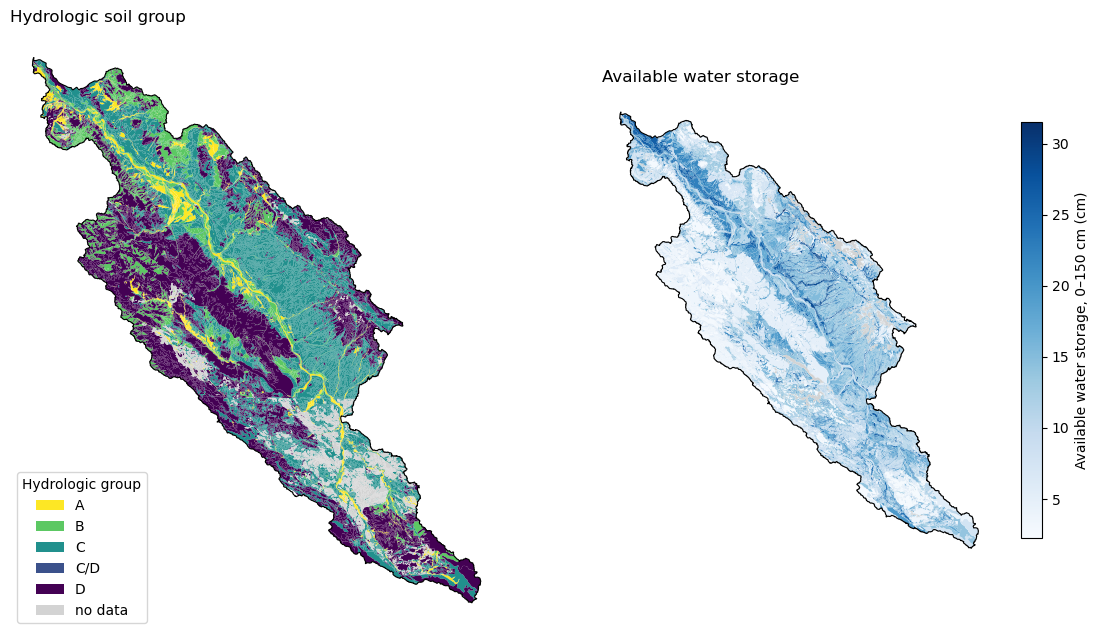

In [27]:
soil = soils.to_crs(3310)

# Categories in their natural order, not alphabetical
order = ["A", "A/D", "B", "B/D", "C", "C/D", "D"]
present = [c for c in order if c in set(soil["hydgrpdcd"].dropna())]
soil["hydgrp"] = pd.Categorical(soil["hydgrpdcd"], categories=present, ordered=True)

fig, axes = plt.subplots(1, 2, figsize=(14, 9))

soil.plot(ax=axes[0], column="hydgrp", cmap="viridis_r", linewidth=0, legend=True,
          legend_kwds={"title": "Hydrologic group", "loc": "lower left"},
          missing_kwds={"color": "lightgrey", "label": "no data"})

soil.plot(ax=axes[1], column="aws0150wta", cmap="Blues", linewidth=0, legend=True,
          legend_kwds={"label": "Available water storage, 0–150 cm (cm)", "shrink": 0.6},
          missing_kwds={"color": "lightgrey"})

for ax, title in zip(axes, ["Hydrologic soil group", "Available water storage"]):
    huc8.to_crs(3310).boundary.plot(ax=ax, color="black", linewidth=0.8)
    ax.set_title(title, loc="left")
    ax.set_axis_off()


#### INMP data

Load and clip the INMP data.

In [28]:
inmp_full = io.load_or_build(full_dir, layer_names, build=lambda: inmp.fetch.fetch_INMP_data(INMP_url, layer_key))

inmp_clipped = io.load_or_build(clipped_dir, layer_names, build = lambda: {name: spatial.clip_layer(gdf, huc8) for name, gdf in inmp_full.items()})